# TDI/WDM Pipeline Example

This notebook runs the reusable TDI/WDM post-processing stage from `scripts/tdi_wdm_pipeline.py`. It expects the main link/TDI outputs from `run_lisa_link_simulation` and produces multi-resolution WDM maps for links, XYZ, AET, plus noisy A/E maps weighted by the noisy T-channel noise proxy.

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "scripts":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.lisa_link_simulation import LisaLinkSimulationConfig, load_npz_waveform, run_lisa_link_simulation
from scripts.tdi_wdm_pipeline import TDIWDMPipelineConfig, WDMResolution, run_tdi_wdm_pipeline

PROJECT_ROOT

PosixPath('/Users/shubhanshutiwari/IdeaProjects/LISA-TF')

## Optional: Run The Main Link/TDI Pipeline

Set `RUN_MAIN_LINK_PIPELINE = True` if `WORK_DIR` does not already contain the main pipeline CSV/HDF5 outputs.

In [3]:
WORK_DIR = PROJECT_ROOT / "lisa_link_sim" / "script_run"
RUN_MAIN_LINK_PIPELINE = False

if RUN_MAIN_LINK_PIPELINE:
    waveform_file = PROJECT_ROOT / "lisa_link_sim" / "inputs" / "my_waveform.npz"
    t, hplus, hcross = load_npz_waveform(waveform_file)
    link_config = LisaLinkSimulationConfig(
        dt=0.1,
        science_duration=100_000.0,
        burn_in_seconds=600.0,
        frequency_low_hz=1e-5,
        frequency_high_hz=1e-2,
        orbit_duration_factor=5.0,
        orbit_dt=600.0,
        central_freq_hz=2.816e14,
        seed=12345,
    )
    link_products = run_lisa_link_simulation(t, hplus, hcross, work_dir=WORK_DIR, config=link_config, make_plots=True)
    display(link_products.diagnostics)

required = [
    WORK_DIR / "outputs" / "six_links_noisy.csv",
    WORK_DIR / "outputs" / "six_links_gw_only.csv",
    WORK_DIR / "outputs" / "tdi_michelson_XYZ_AET.csv",
    WORK_DIR / "outputs" / "tdi_gw_only_XYZ_AET.csv",
]
missing = [path for path in required if not path.exists()]
if missing:
    raise FileNotFoundError("Missing main pipeline outputs. Set RUN_MAIN_LINK_PIPELINE = True or point WORK_DIR at an existing run: " + str(missing))

WORK_DIR

PosixPath('/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run')

## Configure WDM Resolutions

Use the short list for a quick run. Replace `resolutions=FAST_RESOLUTIONS` with the default by omitting `resolutions` for the full multi-resolution grid.

In [4]:
FAST_RESOLUTIONS = (
    WDMResolution("dt1_M256", 1.0, 256),
    WDMResolution("dt2_M1024", 2.0, 1024),
    WDMResolution("dt10_M4096", 10.0, 4096),
)

wdm_config = TDIWDMPipelineConfig(
    tdi_suffix="2",
    resolutions=FAST_RESOLUTIONS,
    low_freq_cut=1e-5,
    high_freq_cut=1e-2,
    make_grid_plots=True,
    make_t_weighted_plots=True,
    make_best_pixel_plots=True,
    save_raw_power=True,
    save_normalized_power=True,
)

wdm_config

TDIWDMPipelineConfig(tdi_suffix='2', resolutions=(WDMResolution(label='dt1_M256', target_dt=1.0, M=256), WDMResolution(label='dt2_M1024', target_dt=2.0, M=1024), WDMResolution(label='dt10_M4096', target_dt=10.0, M=4096)), wdm_k=32, wdm_beta_order=6, wdm_precision=6, wdm_backend='numba', low_freq_cut=1e-05, high_freq_cut=0.01, signal_threshold_fraction=0.001, offsource_guard_seconds=500.0, min_noise_floor=1e-300, save_raw_power=True, save_normalized_power=True, make_grid_plots=True, make_t_weighted_plots=True, make_best_pixel_plots=True, best_pixel_time_bins=240, best_pixel_freq_bins=180)

## Run TDI/WDM And T-Weighted A/E

In [5]:
wdm_products = run_tdi_wdm_pipeline(WORK_DIR, config=wdm_config)
wdm_products.diagnostics

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/scripts/tdi_wdm_pipeline.py:621: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/shubhanshutiwari/IdeaProjects/LISA-TF/scripts/tdi_wdm_pipeline.py:663: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


{'samples': 1000000,
 'dt': 0.10000000149011612,
 'span_seconds': 99999.89999999851,
 'signal_peak_lisa': 61421184.577664,
 'signal_peak_rel': 49445.20000000298,
 'signal_window_start_lisa': 61417549.577664,
 'signal_window_stop_lisa': 61422923.377664,
 'signal_window_start_rel': 45810.20000000298,
 'signal_window_stop_rel': 51184.0,
 'n_wdm_rows': 72,
 'n_t_weighted_rows': 6,
 'n_bestpixel_rows': 26}

## Output Files

In [6]:
for name, path in wdm_products.paths.__dict__.items():
    if name.endswith(("csv", "npz")):
        print(f"{name:24s} {path}")

noisy_links_csv          /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/six_links_noisy.csv
gw_links_csv             /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/six_links_gw_only.csv
noisy_tdi_csv            /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/tdi_michelson_XYZ_AET.csv
gw_tdi_csv               /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/tdi_gw_only_XYZ_AET.csv
multires_stats_csv       /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/multires_wdm_links_xyz_aet_stats.csv
multires_maps_npz        /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/multires_wdm_links_xyz_aet_maps.npz
t_weighted_stats_csv     /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/multires_wdm_AE_Twhiten_stats.csv
t_weighted_maps_npz      /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_

## Ranked Channels

In [7]:
summary_cols = [
    "source", "group", "channel", "resolution", "target_dt_s", "wdm_M", "wdm_df_hz",
    "reaches_1e-5_hz", "signal_over_offsource_mean", "signal_norm_power_mean", "signal_norm_power_max",
]
display(
    wdm_products.wdm_summary[summary_cols]
    .sort_values("signal_over_offsource_mean", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

display(
    wdm_products.t_weighted_summary
    .sort_values("t_weighted_signal_over_offsource_mean", ascending=False)
    .reset_index(drop=True)
)

,source,group,channel,resolution,target_dt_s,wdm_M,wdm_df_hz,reaches_1e-5_hz,signal_over_offsource_mean,signal_norm_power_mean,signal_norm_power_max
0,gw_only,links,21,dt1_M256,1.0,256,0.001953,False,3.566735e+17,2.246881e+292,5.828031e+293
1,gw_only,links,12,dt1_M256,1.0,256,0.001953,False,3.449317e+17,2.272663e+292,5.925507e+293
2,gw_only,links,13,dt1_M256,1.0,256,0.001953,False,1.946115e+17,2.422511e+292,6.197619e+293
3,gw_only,links,31,dt1_M256,1.0,256,0.001953,False,1.928362e+17,2.446589e+292,6.286780e+293
4,gw_only,links,23,dt1_M256,1.0,256,0.001953,False,1.110601e+17,1.419511e+292,3.639213e+293
5,gw_only,links,32,dt1_M256,1.0,256,0.001953,False,1.061794e+17,1.450638e+292,3.755519e+293
6,gw_only,links,23,dt2_M1024,2.0,1024,0.000244,False,2.709195e+14,1.493638e+292,1.569789e+293
7,gw_only,links,21,dt2_M1024,2.0,1024,0.000244,False,2.670651e+14,2.372299e+292,2.488721e+293
8,gw_only,links,13,dt2_M1024,2.0,1024,0.000244,False,2.642836e+14,2.531258e+292,2.663949e+293
9,gw_only,links,12,dt2_M1024,2.0,1024,0.000244,False,2.605580e+14,2.387052e+292,2.503686e+293


,source,group,channel,weighting_proxy,resolution,target_dt_s,wdm_M,wdm_df_hz,first_positive_freq_hz,reaches_1e-5_hz,wdm_dt_tf_s,n_frequency_layers,n_signal_time_layers,signal_tf_pixels,t_weighted_signal_mean,t_weighted_signal_median,t_weighted_signal_max,t_weighted_offsource_mean,t_weighted_signal_over_offsource_mean
0,noisy,AET,A,T,dt1_M256,1.0,256,0.001953,0.001953,False,255.754480,5,21,105,30208.301758,802.245125,613546.033947,51.301954,588.833358
1,noisy,AET,A,T,dt2_M1024,2.0,1024,0.000244,0.000244,False,2040.816357,40,3,120,34679.530668,214.951991,410320.096074,60.524959,572.979003
2,noisy,AET,E,T,dt1_M256,1.0,256,0.001953,0.001953,False,255.754480,5,21,105,28805.217864,791.880040,583115.285338,93.710181,307.386215
3,noisy,AET,E,T,dt2_M1024,2.0,1024,0.000244,0.000244,False,2040.816357,40,3,120,34238.189161,410.259217,412029.105308,112.993425,303.010455
4,noisy,AET,A,T,dt10_M4096,10.0,4096,0.000012,0.000012,False,37811.539025,819,0,0,NaN,NaN,NaN,114.546293,NaN
5,noisy,AET,E,T,dt10_M4096,10.0,4096,0.000012,0.000012,False,37811.539025,819,0,0,NaN,NaN,NaN,236.875214,NaN


## Preview Saved Plots

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/plots/15_multires_grid_noisy_AET.png


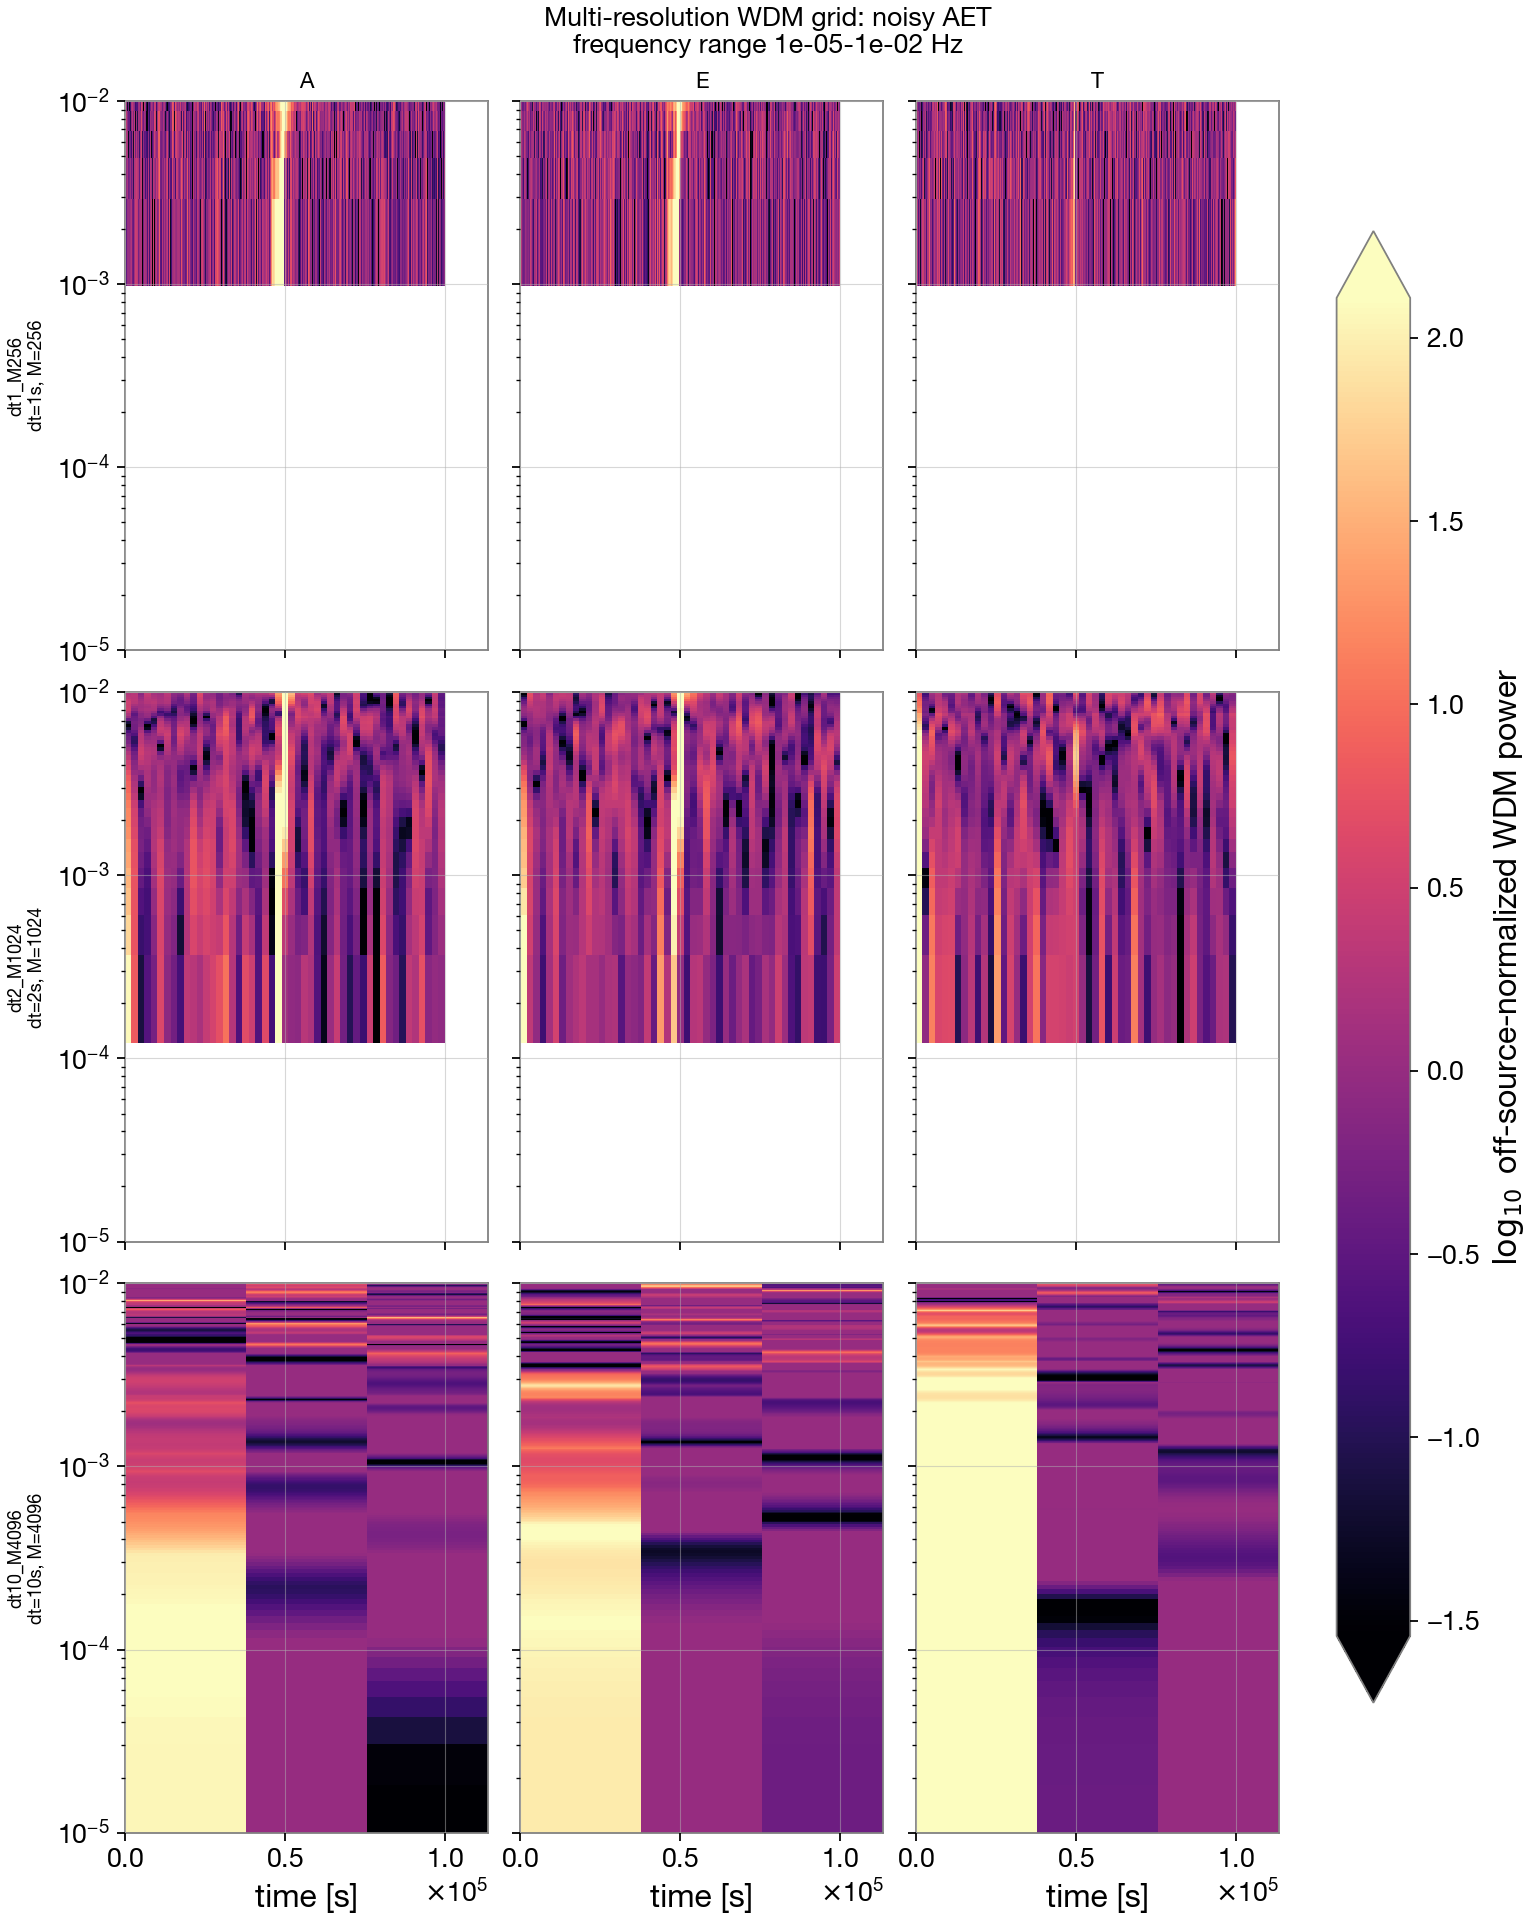

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/plots/15_multires_grid_noisy_AE_Twhiten.png


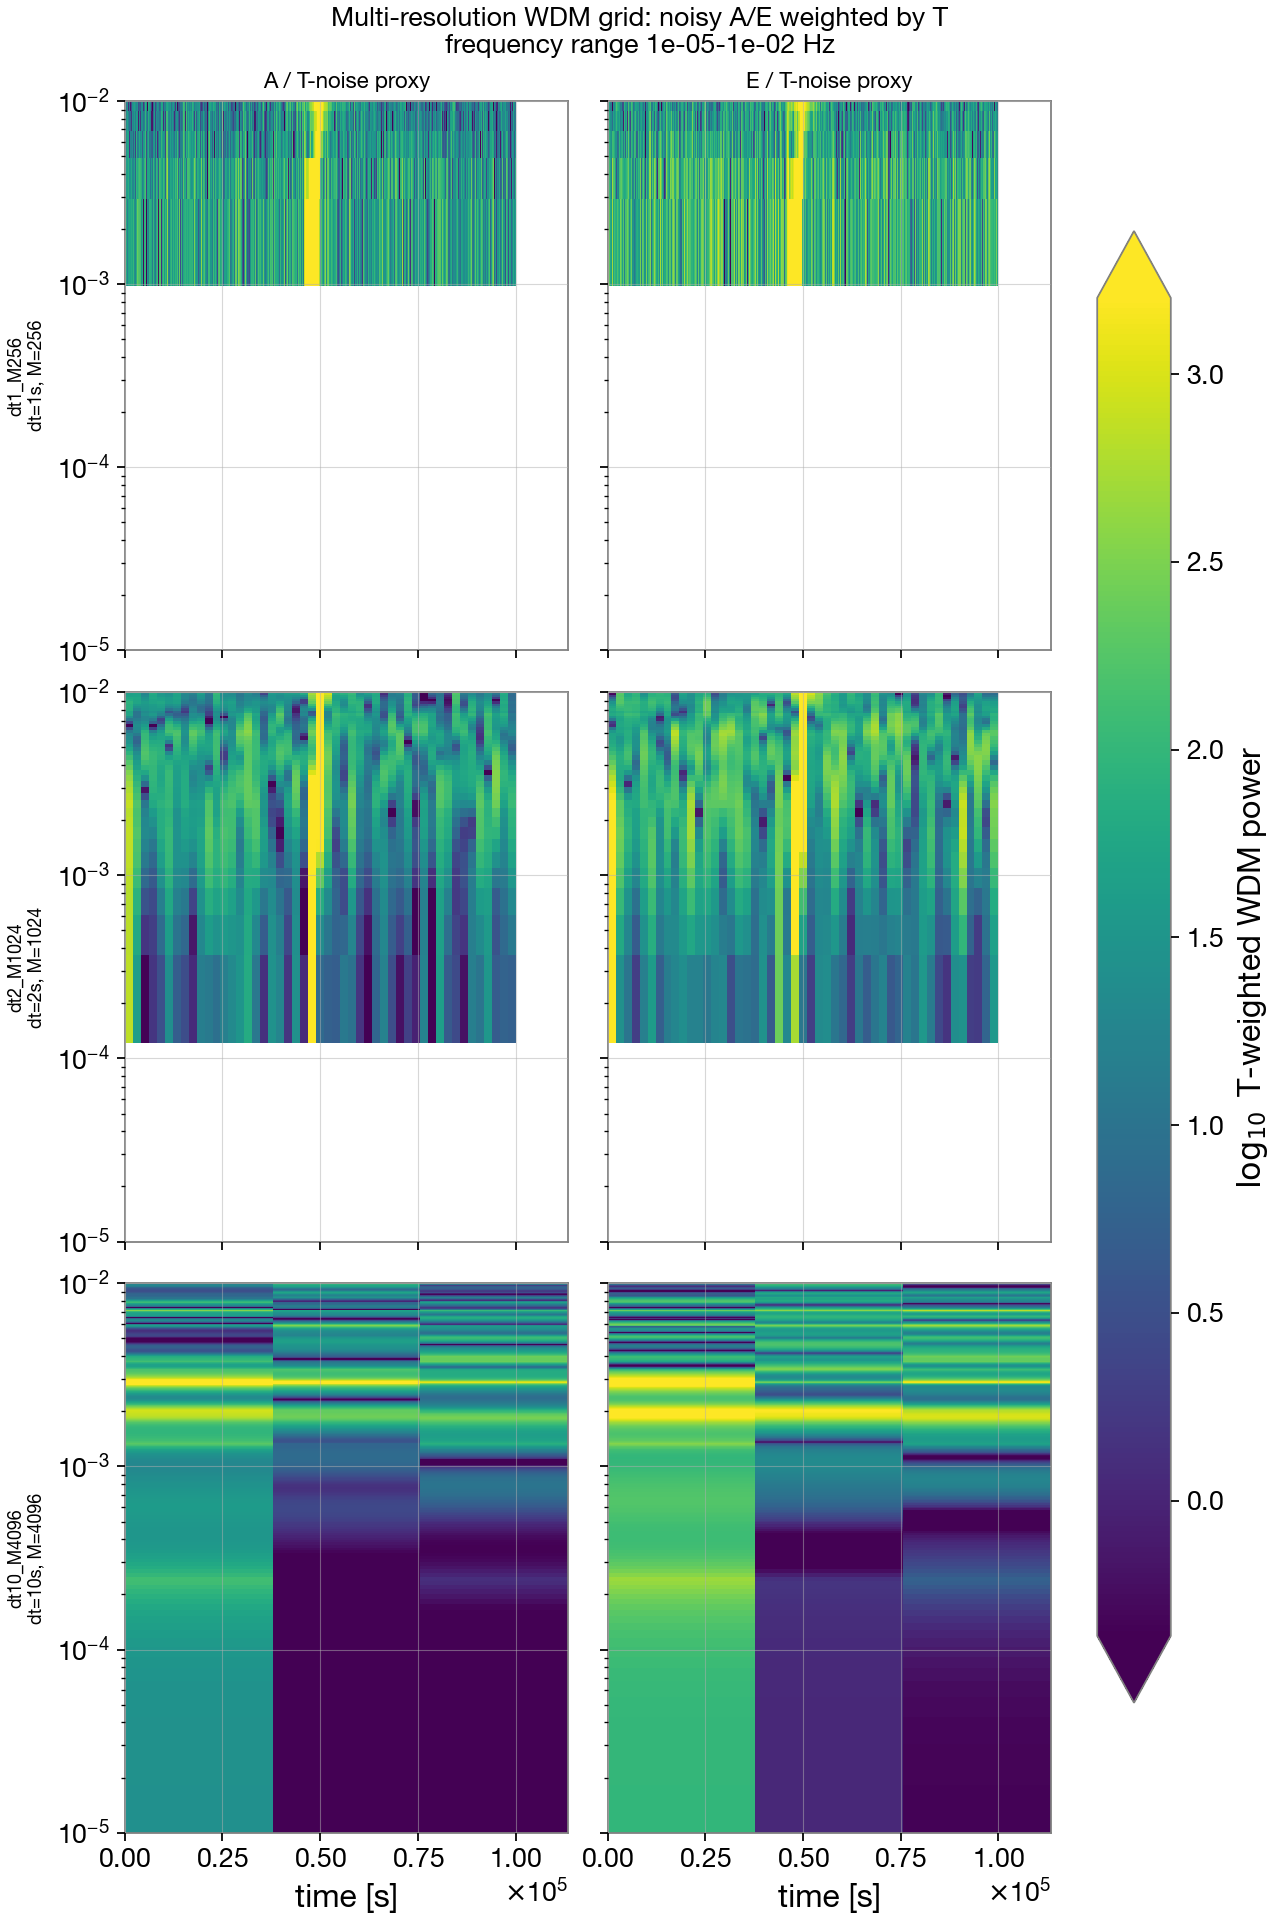

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/plots/14_bestpixel_wdm_noisy_AE_Twhiten.png


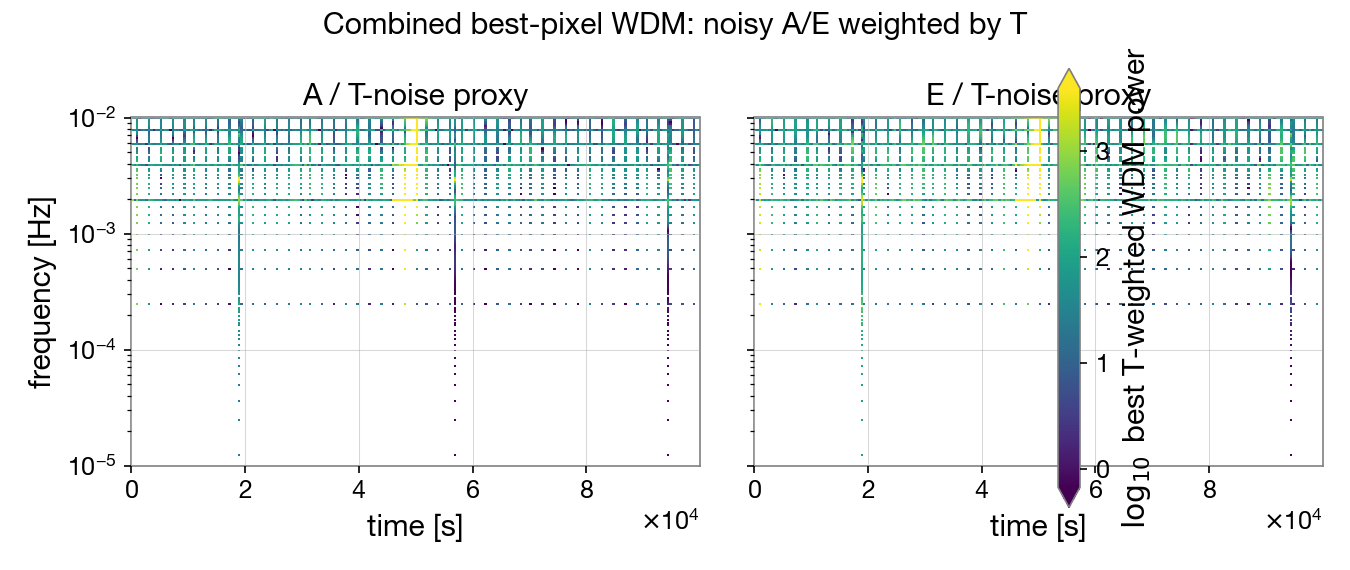

In [8]:
from IPython.display import Image, display

plot_candidates = [
    wdm_products.paths.plot_dir / "15_multires_grid_noisy_AET.png",
    wdm_products.paths.plot_dir / "15_multires_grid_noisy_AE_Twhiten.png",
    wdm_products.paths.plot_dir / "14_bestpixel_wdm_noisy_AE_Twhiten.png",
]

for plot in plot_candidates:
    if plot.exists():
        print(plot)
        display(Image(filename=str(plot)))

## Plot 12-Style T-Weighted Peak Zoom

This reproduces the `12_1e5_multires_wdm_AE_Twhiten_peak_zoom.png` style: each panel is centered on the noisy A/E T-weighted WDM peak, with the GW-only T-weighted signal peak overlaid.

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/plots/12_multires_wdm_AE_Twhiten_peak_zoom.png
/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/script_run/outputs/12_multires_wdm_AE_Twhiten_peak_zoom_stats.csv


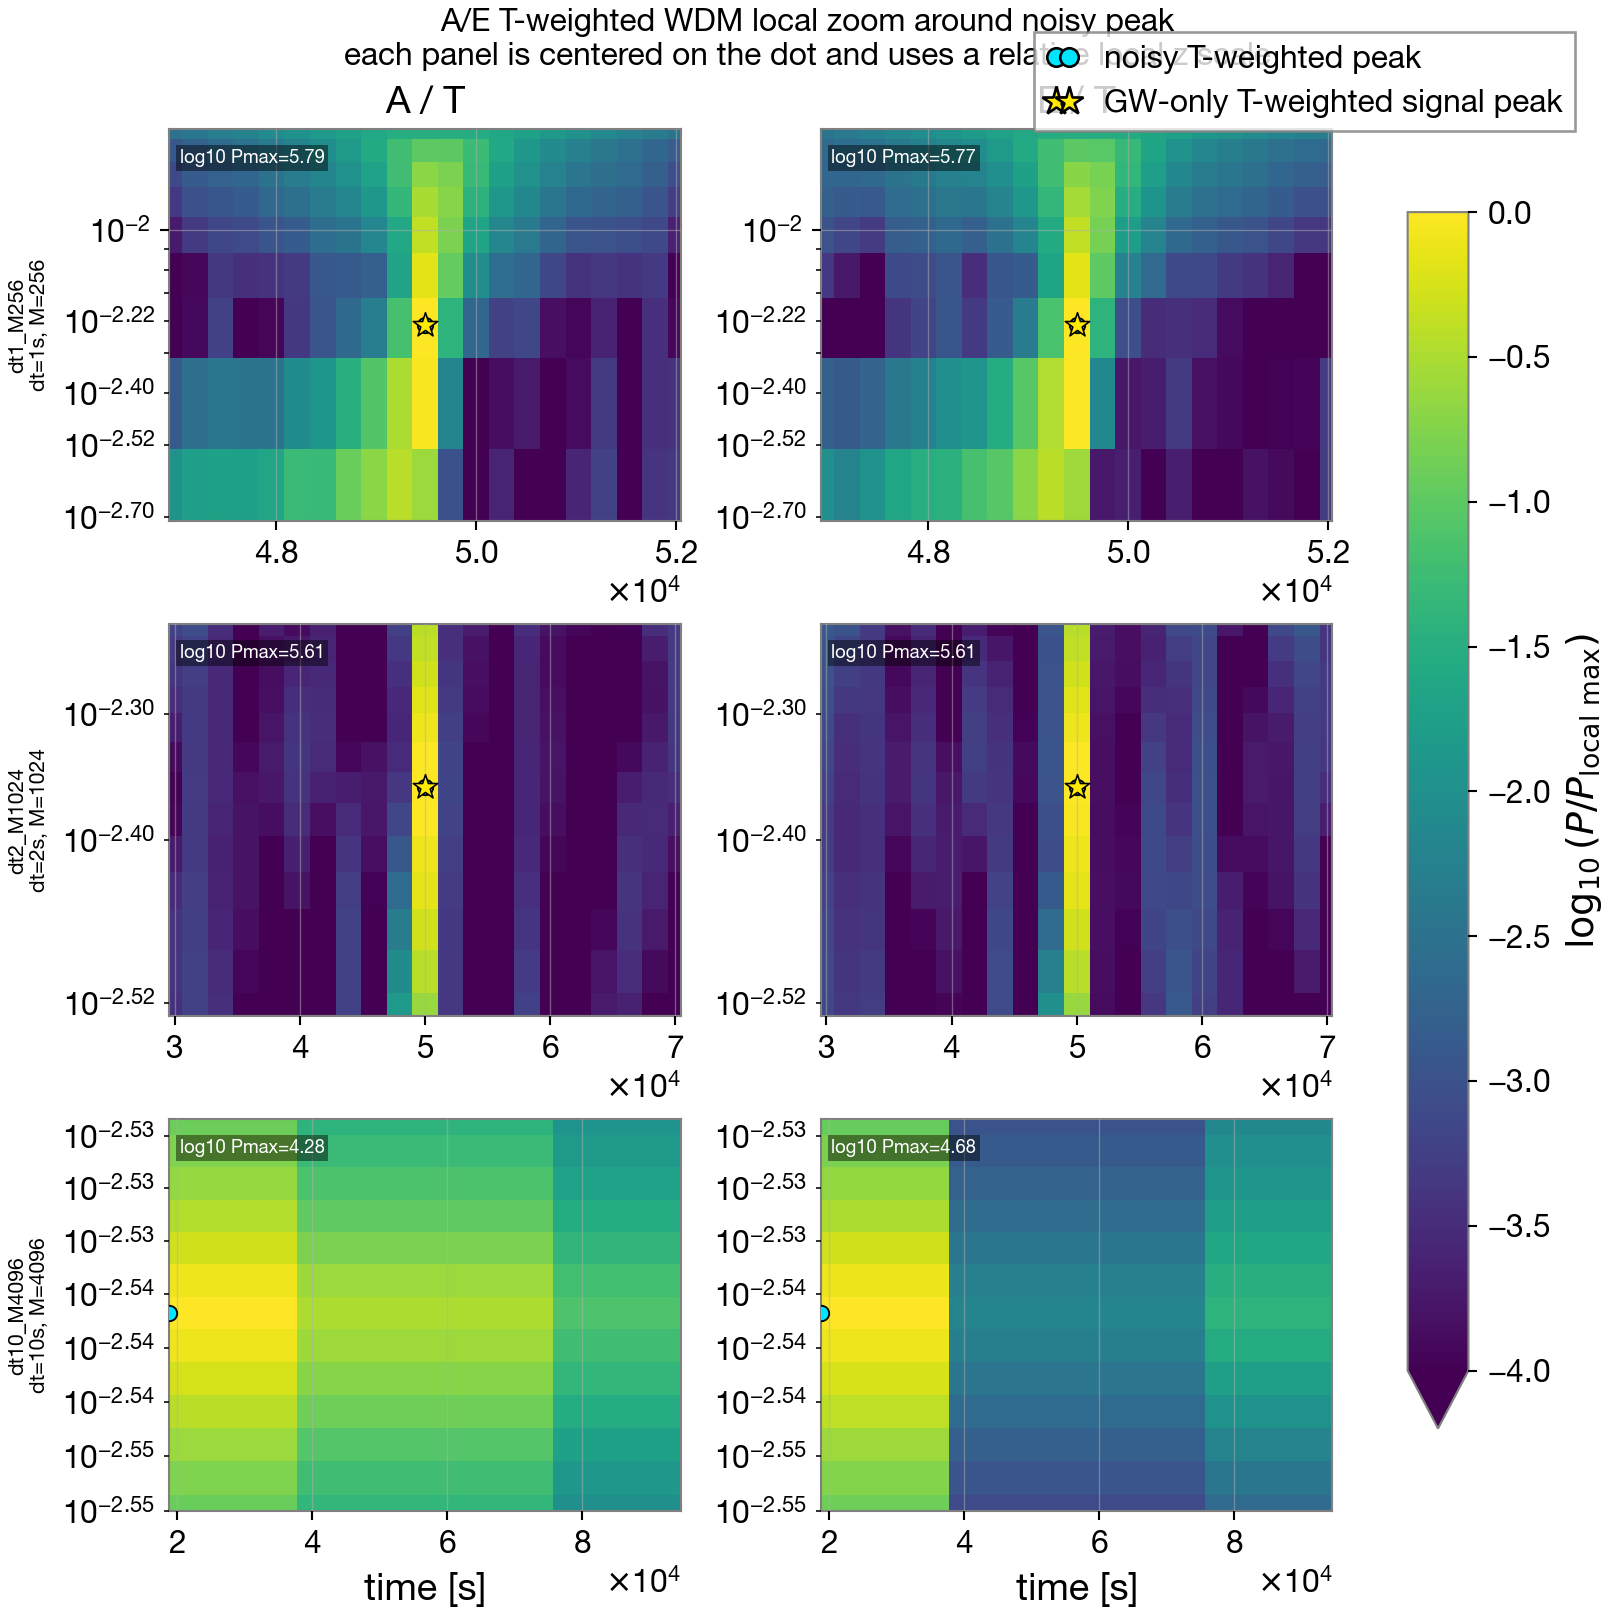

,channel,resolution,target_dt_s,wdm_M,noisy_twhiten_peak_time_s,noisy_twhiten_peak_frequency_hz,noisy_twhiten_peak_power,signal_twhiten_peak_time_s,signal_twhiten_peak_frequency_hz,signal_twhiten_peak_power
0,A,dt1_M256,1.0,256,49488.491786,0.005859,613546.033947,49488.491786,0.005859,618226.824645
1,E,dt1_M256,1.0,256,49488.491786,0.005859,583115.285338,49488.491786,0.005859,577919.336738
2,A,dt2_M1024,2.0,1024,50000.000745,0.004395,410320.096074,50000.000745,0.004395,422313.667068
3,E,dt2_M1024,2.0,1024,50000.000745,0.004395,412029.105308,50000.000745,0.004395,405548.754318
4,A,dt10_M4096,10.0,4096,18905.769512,0.002893,18915.779199,NaN,NaN,NaN
5,E,dt10_M4096,10.0,4096,18905.769512,0.002893,48181.622634,NaN,NaN,NaN


In [10]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ZOOM_TIME_HALF_BINS = 10
ZOOM_FREQ_HALF_BINS = 6
ZOOM_REL_LOG_FLOOR = -4.0
ANALYSIS_EDGE_GUARD_SECONDS = 10_000.0

signal_window_rel = (
    float(wdm_products.diagnostics["signal_window_start_rel"]),
    float(wdm_products.diagnostics["signal_window_stop_rel"]),
)


def centers_to_edges(values):
    values = np.asarray(values, dtype=float)
    if values.size == 1:
        width = 1.0
        return np.array([values[0] - 0.5 * width, values[0] + 0.5 * width])
    edges = np.empty(values.size + 1, dtype=float)
    edges[1:-1] = 0.5 * (values[:-1] + values[1:])
    edges[0] = values[0] - 0.5 * (values[1] - values[0])
    edges[-1] = values[-1] + 0.5 * (values[-1] - values[-2])
    return np.maximum(edges, np.nextafter(0.0, 1.0))


def centered_slice(size, center, half_width):
    start = max(0, int(center) - half_width)
    stop = min(size, int(center) + half_width + 1)
    return slice(start, stop)


def peak_pixel(power, times_rel, freqs, *, edge_guard_s, time_window=None):
    fmask = (freqs >= wdm_config.low_freq_cut) & (freqs <= wdm_config.high_freq_cut)
    tmask = (times_rel >= edge_guard_s) & (times_rel <= times_rel[-1] - edge_guard_s)
    if time_window is not None:
        tmask &= (times_rel >= time_window[0]) & (times_rel <= time_window[1])
    if not np.any(fmask) or not np.any(tmask):
        return {"time_s": np.nan, "frequency_hz": np.nan, "power": np.nan}
    sub = power[np.ix_(fmask, tmask)]
    if sub.size == 0 or not np.any(np.isfinite(sub)):
        return {"time_s": np.nan, "frequency_hz": np.nan, "power": np.nan}
    local_f, local_t = np.unravel_index(int(np.nanargmax(sub)), sub.shape)
    freq_indices = np.flatnonzero(fmask)
    time_indices = np.flatnonzero(tmask)
    f_idx = int(freq_indices[local_f])
    t_idx = int(time_indices[local_t])
    return {"time_s": float(times_rel[t_idx]), "frequency_hz": float(freqs[f_idx]), "power": float(power[f_idx, t_idx])}


def peak_zoom(power, times_rel, freqs, peak_time, peak_freq):
    if not np.isfinite(peak_time) or not np.isfinite(peak_freq):
        return np.array([]), np.array([]), np.empty((0, 0))
    time_idx = int(np.nanargmin(np.abs(times_rel - peak_time)))
    freq_idx = int(np.nanargmin(np.abs(freqs - peak_freq)))
    ts = centered_slice(times_rel.size, time_idx, ZOOM_TIME_HALF_BINS)
    fs = centered_slice(freqs.size, freq_idx, ZOOM_FREQ_HALF_BINS)
    crop_freqs = freqs[fs]
    crop = power[fs, ts]
    positive = crop_freqs > 0.0
    crop_freqs = crop_freqs[positive]
    crop = crop[positive]
    finite = np.isfinite(crop) & (crop > 0)
    if not np.any(finite):
        return times_rel[ts], crop_freqs, np.full(crop.shape, np.nan)
    local_max = float(np.nanmax(crop[finite]))
    image = np.log10(np.maximum(crop / local_max, 1e-30))
    return times_rel[ts], crop_freqs, np.maximum(image, ZOOM_REL_LOG_FLOOR)


rows = []
zoom_prepared = {}

for r, resolution in enumerate(wdm_config.resolutions):
    t_prod = wdm_products.wdm_products[("noisy", "AET", "T", resolution.label)]
    t_noise_floor = np.asarray(t_prod["noise_floor"], dtype=float)
    for c, channel in enumerate(["A", "E"]):
        noisy_prod = wdm_products.wdm_products[("noisy", "AET", channel, resolution.label)]
        gw_prod = wdm_products.wdm_products[("gw_only", "AET", channel, resolution.label)]
        times_rel = np.asarray(noisy_prod["times_rel"], dtype=float)
        freqs = np.asarray(noisy_prod["freqs_hz"], dtype=float)
        noisy_twhiten = np.asarray(noisy_prod["power"], dtype=float) / np.maximum(t_noise_floor[:, None], wdm_config.min_noise_floor)
        signal_twhiten = np.asarray(gw_prod["power"], dtype=float) / np.maximum(t_noise_floor[:, None], wdm_config.min_noise_floor)

        noisy_peak = peak_pixel(noisy_twhiten, times_rel, freqs, edge_guard_s=ANALYSIS_EDGE_GUARD_SECONDS)
        signal_peak = peak_pixel(
            signal_twhiten,
            times_rel,
            freqs,
            edge_guard_s=ANALYSIS_EDGE_GUARD_SECONDS,
            time_window=signal_window_rel,
        )
        zoom_prepared[(r, c)] = peak_zoom(
            noisy_twhiten,
            times_rel,
            freqs,
            noisy_peak["time_s"],
            noisy_peak["frequency_hz"],
        )
        rows.append(
            {
                "channel": channel,
                "resolution": resolution.label,
                "target_dt_s": resolution.target_dt,
                "wdm_M": resolution.M,
                "noisy_twhiten_peak_time_s": noisy_peak["time_s"],
                "noisy_twhiten_peak_frequency_hz": noisy_peak["frequency_hz"],
                "noisy_twhiten_peak_power": noisy_peak["power"],
                "signal_twhiten_peak_time_s": signal_peak["time_s"],
                "signal_twhiten_peak_frequency_hz": signal_peak["frequency_hz"],
                "signal_twhiten_peak_power": signal_peak["power"],
            }
        )

peak_df = pd.DataFrame(rows)
fig, axes = plt.subplots(
    len(wdm_config.resolutions),
    2,
    figsize=(8.5, max(1.35 * len(wdm_config.resolutions), 8.5)),
    sharex=False,
    sharey=False,
    constrained_layout=True,
)
axes = np.asarray(axes).reshape(len(wdm_config.resolutions), 2)
zoom_im = None

for r, resolution in enumerate(wdm_config.resolutions):
    for c, channel in enumerate(["A", "E"]):
        ax = axes[r, c]
        times, freqs, image = zoom_prepared[(r, c)]
        row = peak_df[(peak_df["resolution"] == resolution.label) & (peak_df["channel"] == channel)].iloc[0]
        if image.size:
            zoom_im = ax.pcolormesh(
                centers_to_edges(times),
                centers_to_edges(freqs),
                image,
                shading="auto",
                cmap="viridis",
                vmin=ZOOM_REL_LOG_FLOOR,
                vmax=0.0,
            )
            ax.scatter(
                row["noisy_twhiten_peak_time_s"],
                row["noisy_twhiten_peak_frequency_hz"],
                marker="o",
                s=34,
                facecolor="#00e5ff",
                edgecolor="black",
                linewidth=0.7,
                zorder=5,
            )
            if np.isfinite(row["signal_twhiten_peak_time_s"]) and np.isfinite(row["signal_twhiten_peak_frequency_hz"]):
                ax.scatter(
                    row["signal_twhiten_peak_time_s"],
                    row["signal_twhiten_peak_frequency_hz"],
                    marker="*",
                    s=95,
                    facecolor="#ffea00",
                    edgecolor="black",
                    linewidth=0.6,
                    zorder=6,
                )
            ax.set_yscale("log")
            ax.set_xlim(float(times[0]), float(times[-1]))
            ax.set_ylim(float(freqs[0]), float(freqs[-1]))
            ax.text(
                0.02,
                0.95,
                f"log10 Pmax={np.log10(row['noisy_twhiten_peak_power']):.2f}",
                transform=ax.transAxes,
                va="top",
                ha="left",
                fontsize=7,
                color="white",
                bbox={"facecolor": "black", "alpha": 0.45, "edgecolor": "none", "pad": 1.5},
            )
        else:
            ax.text(0.5, 0.5, "no finite peak", transform=ax.transAxes, ha="center", va="center")
        if r == 0:
            ax.set_title(f"{channel} / T")
        if c == 0:
            ax.set_ylabel(f"{resolution.label}\ndt={resolution.target_dt:g}s, M={resolution.M}", fontsize=8)
        if r == len(wdm_config.resolutions) - 1:
            ax.set_xlabel("time [s]")

fig.legend(
    handles=[
        mlines.Line2D([], [], color="#00e5ff", marker="o", linestyle="None", markeredgecolor="black", markersize=7, label="noisy T-weighted peak"),
        mlines.Line2D([], [], color="#ffea00", marker="*", linestyle="None", markeredgecolor="black", markersize=11, label="GW-only T-weighted signal peak"),
    ],
    loc="upper right",
    bbox_to_anchor=(0.985, 0.99),
)
if zoom_im is not None:
    cbar = fig.colorbar(zoom_im, ax=axes, shrink=0.88, extend="min")
    cbar.set_label(r"$\log_{10}(P/P_{\rm local\ max})$")
fig.suptitle(
    "A/E T-weighted WDM local zoom around noisy peak\n"
    "each panel is centered on the dot and uses a relative local z scale",
    fontsize=12,
)

plot12_file = wdm_products.paths.plot_dir / "12_multires_wdm_AE_Twhiten_peak_zoom.png"
stats12_file = wdm_products.paths.output_dir / "12_multires_wdm_AE_Twhiten_peak_zoom_stats.csv"
fig.savefig(plot12_file, dpi=190)
peak_df.to_csv(stats12_file, index=False)
plt.close(fig)

print(plot12_file)
print(stats12_file)
display(Image(filename=str(plot12_file)))
display(peak_df)
